E-commerce Supply Chain Analytics & Demand Forecasting


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [2]:
os.chdir(r'E:\Project 2026\raw data\archive')

customers = pd.read_csv(r'olist_customers_dataset.csv')
geolocations = pd.read_csv(r'olist_geolocation_dataset.csv')
order_items = pd.read_csv(r'olist_order_items_dataset.csv')
order_payments = pd.read_csv(r'olist_order_payments_dataset.csv')
order_reviews = pd.read_csv(r'olist_order_reviews_dataset.csv')
orders = pd.read_csv(r'olist_orders_dataset.csv')
products = pd.read_csv(r'olist_products_dataset.csv')
sellers = pd.read_csv(r'olist_sellers_dataset.csv')
category_name_translation = pd.read_csv(r'product_category_name_translation.csv')

In [3]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Business insight:

2965 null delivered dates → these are cancelled/pending orders
We'll filter these out when calculating delivery metrics

In [4]:
orders.groupby('order_status')[['order_approved_at','order_delivered_carrier_date',
                                'order_delivered_customer_date']].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


**Insight:** Missing dates are explained by order status (canceled, unavailable, in-transit orders never reached those stages), so they are genuine, not errors. Only 8 delivered orders lack a delivery date; these are excluded from delivery KPIs. Demand forecasting uses the purchase date, which has no missing values.

In [5]:
date_cols = ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
             'order_delivered_customer_date','order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

2016-09-04 00:00:00 2018-09-03 00:00:00


<Axes: title={'center': 'Daily Orders'}, xlabel='date'>

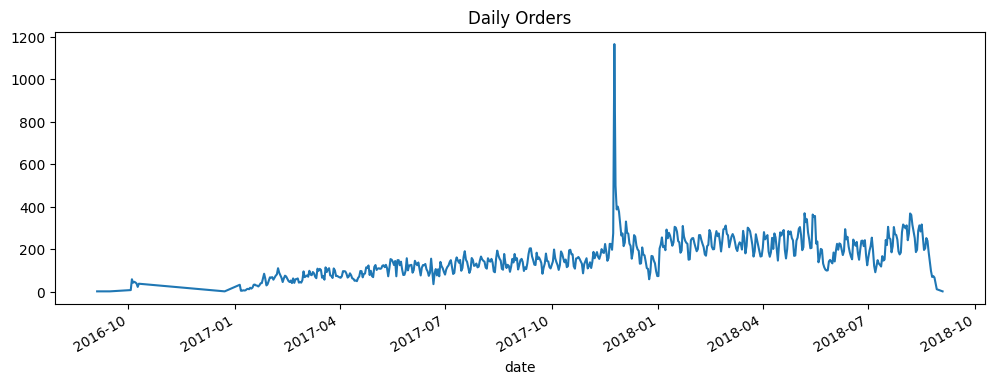

In [6]:
demand = orders[~orders['order_status'].isin(['canceled','unavailable'])].copy()
demand['date'] = demand['order_purchase_timestamp'].dt.date
daily = demand.groupby('date').size().rename('orders').reset_index()
daily['date'] = pd.to_datetime(daily['date'])
print(daily['date'].min(), daily['date'].max())
daily.set_index('date')['orders'].plot(figsize=(12,4), title='Daily Orders')


Phase 1
Q1: How many orders, and which period?

In [7]:
print('Total orders:', orders['order_id'].nunique())
print('Period:', orders['order_purchase_timestamp'].min().date(), 'to', orders['order_purchase_timestamp'].max().date())
print(orders['order_status'].value_counts(normalize=True).mul(100).round(1))

Total orders: 99441
Period: 2016-09-04 to 2018-10-17
order_status
delivered      97.0
shipped         1.1
canceled        0.6
unavailable     0.6
invoiced        0.3
processing      0.3
created         0.0
approved        0.0
Name: proportion, dtype: float64


**Insight:** 99,441 orders from Sep 2016 to Oct 2018. 97% were delivered, and only 1.2% were canceled or unavailable, so fulfilment is reliable overall. The first and last months have sparse data and will be trimmed for forecasting.

Q2: Which states have the most orders?

customer_state
SP    42.0
RJ    12.9
MG    11.7
RS     5.5
PR     5.1
SC     3.7
BA     3.4
DF     2.2
ES     2.0
GO     2.0
Name: count, dtype: float64


<Axes: title={'center': 'Top 10 States by Orders'}, xlabel='customer_state'>

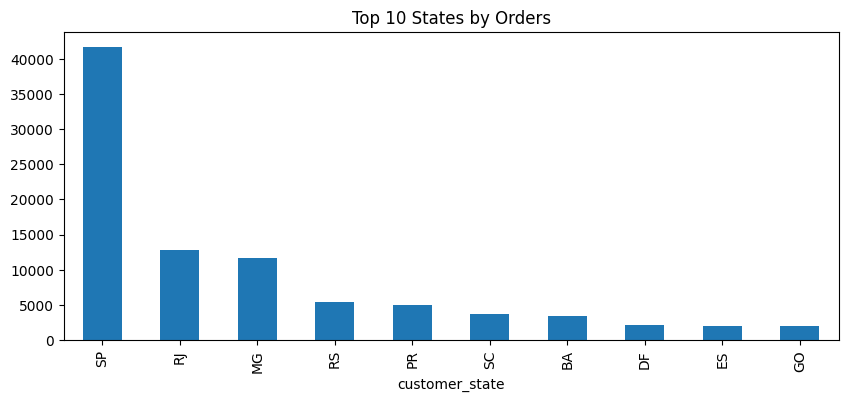

In [8]:
state = orders.merge(customers, on='customer_id')['customer_state'].value_counts()
print((state / state.sum() * 100).round(1).head(10))
state.head(10).plot(kind='bar', figsize=(10,4), title='Top 10 States by Orders')

**Insight:** Demand is highly concentrated: SP alone accounts for 42% of orders, and the top 3 states (SP, RJ, MG) for ~67%. The top 10 states make up ~90%, so delivery and inventory planning should prioritise the Southeast region.

Q3. What are top selling categories?

In [9]:
items = (order_items.merge(products, on='product_id')
         .merge(category_name_translation, on='product_category_name', how='left'))
top_cat = items['product_category_name_english'].value_counts()
print((top_cat / top_cat.sum() * 100).round(1).head(10))

product_category_name_english
bed_bath_table           10.0
health_beauty             8.7
sports_leisure            7.8
furniture_decor           7.5
computers_accessories     7.0
housewares                6.3
watches_gifts             5.4
telephony                 4.1
garden_tools              3.9
auto                      3.8
Name: count, dtype: float64


**Insight:** Top 10 categories make up ~65% of items sold. Home-related categories (bed_bath_table, furniture_decor, housewares) together account for ~24%, the largest demand group, so they should get priority in forecasting and stock planning.

Q4. How many late deliveries?


In [10]:
d = orders[(orders['order_status']=='delivered') & orders['order_delivered_customer_date'].notna()].copy()
d['late'] = d['order_delivered_customer_date'] > d['order_estimated_delivery_date']
d['delivery_days'] = (d['order_delivered_customer_date'] - d['order_purchase_timestamp']).dt.days
print('Late delivery %:', round(d['late'].mean()*100, 1))
print('Avg delivery days:', round(d['delivery_days'].mean(), 1))

Late delivery %: 8.1
Avg delivery days: 12.1


**Insight:** 8.1% of delivered orders arrived after the estimated date, and average delivery time is 12.1 days. Long delivery times suggest scope to improve, especially in states far from the main seller hubs.

Q5. Which sellers perform best?


In [11]:
# Seller performance: orders, late %, avg review (sellers with 30+ orders)
rev = order_reviews.groupby('order_id')['review_score'].mean()
s = order_items[['order_id','seller_id']].drop_duplicates().merge(d[['order_id','late']], on='order_id')
s['review'] = s['order_id'].map(rev)
sellers_perf = (s.groupby('seller_id')
                .agg(orders=('order_id','count'), late_pct=('late','mean'), avg_review=('review','mean'))
                .query('orders >= 30'))
sellers_perf['late_pct'] = (sellers_perf['late_pct']*100).round(1)
sellers_perf['avg_review'] = sellers_perf['avg_review'].round(2)
print('Sellers with 30+ orders:', len(sellers_perf))
print(sellers_perf.sort_values(['avg_review','late_pct'], ascending=[False,True]).head(5))
print(sellers_perf.sort_values(['avg_review','late_pct'], ascending=[True,False]).head(5))
print(sellers_perf[['late_pct','avg_review']].corr().round(2))

Sellers with 30+ orders: 627
                                  orders  late_pct  avg_review
seller_id                                                     
48efc9d94a9834137efd9ea76b065a38      33       0.0        5.00
02f5837340d7eb4f653d676c7256523a      30       3.3        4.83
d13e50eaa47b4cbe9eb81465865d8cfc      66      21.2        4.82
b410bdd36d5db7a65dcd42b7ead933b8      42       2.4        4.81
83e197e95a1bbabc8c75e883ed016c47      46       2.2        4.80
                                  orders  late_pct  avg_review
seller_id                                                     
1ca7077d890b907f89be8c954a02686a     108      22.2        2.39
2eb70248d66e0e3ef83659f71b244378     187      13.9        2.79
a49928bcdf77c55c6d6e05e09a9b4ca5      96      26.0        3.03
972d0f9cf61b499a4812cf0bfa3ad3c4      81      11.1        3.03
54965bbe3e4f07ae045b90b0b8541f52      73      30.1        3.14
            late_pct  avg_review
late_pct        1.00       -0.51
avg_review     -0.51   

**Insight:** Among 627 sellers with 30+ orders, the lowest-rated sellers (avg review 2.4–3.1) have high late delivery rates (11–30%), while top sellers are mostly at 0–3%. Late delivery is a key driver of poor reviews, so improving delivery reliability for low-performing sellers should directly lift customer satisfaction. (Exception: one top seller has 21% late but a 4.82 rating, so product quality can offset delays.)

**Phase 2** SQL analysis

In [12]:
import sqlite3
conn = sqlite3.connect('olist.db') ##made database in project folder
##  created the tables
for name, df in {'orders':orders, 'customers':customers, 'order_items':order_items,
                 'products':products, 'category':category_name_translation,
                 'reviews':order_reviews, 'sellers':sellers}.items():
    df.to_sql(name, conn, if_exists='replace', index=False)

def q(sql): return pd.read_sql(sql, conn)

1. sqlite3.connect('olist.db') created the database.
SQLite is a file-based database built into Python, so there’s no server or installation. When you connect to a file that doesn’t exist yet, SQLite creates it. Check your project folder: you’ll now see a file called olist.db. That one file is the whole database.

2. df.to_sql(name, conn) created the tables.
The loop took each pandas DataFrame (orders, customers and so on) and wrote it into the database as a SQL table, with the column names becoming table columns. So orders the DataFrame became orders the SQL table. if_exists='replace' means that if you run it again, the table is overwritten instead of duplicated.

3. pd.read_sql(sql, conn) ran the query.
It sends your SQL to the database and returns the result as a DataFrame, which is why the output looks like a pandas table. The small q() function is just a shortcut so you don’t have to type pd.read_sql(..., conn) every time.

So the flow is: CSV → pandas DataFrame → SQLite table (in olist.db) → SQL query → DataFrame result. Next time you open the notebook, you can skip the loading step and just sqlite3.connect('olist.db'), because the tables are saved in the file.

About your output: it shows the end of the data collapsing (from ~240 orders a day down to 11, then 1 on 3 Sep). That confirms the last weeks are incomplete, so we’ll trim them for forecasting.

Also notice that 30 Aug to 2 Sep are missing. ROWS BETWEEN 6 PRECEDING counts rows, not calendar days, so around that gap the “7-day” average actually spans more days. That’s the same caveat we discussed in your interview preparation. For a project note:

Q1. Rolling 7 day demand trend (moving average)

In [13]:
## q is for just a shortcut so we don’t have to type pd.read_sql(..., conn) every time.
q("""                       
WITH daily AS (
  SELECT DATE(order_purchase_timestamp) AS day, COUNT(*) AS orders
  FROM orders
  WHERE order_status NOT IN ('canceled','unavailable')
  GROUP BY day
)
SELECT day, orders,
       ROUND(AVG(orders) OVER (ORDER BY day ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 1) AS ma_7d
FROM daily
ORDER BY day
""").tail(10)

,day,orders,ma_7d
604,2018-08-21,239,249.1
605,2018-08-22,186,235.3
606,2018-08-23,142,210.4
607,2018-08-24,97,188.0
608,2018-08-25,69,169.9
609,2018-08-26,73,151.1
610,2018-08-27,66,124.6
611,2018-08-28,39,96.0
612,2018-08-29,11,71.0
613,2018-09-03,1,50.9


**Insight:** The 7-day moving average smooths daily noise and shows the underlying trend. Orders drop sharply after mid-Aug 2018 (to 1 order on 3 Sep), confirming incomplete data at the end. The forecasting period will be trimmed to Jan 2017 – Aug 2018.

Q2. → Month over month growth by category


In [14]:
# monthly CTE: counts orders per category per month, for Jan 2017 to Aug 2018 (the trimmed, complete period).
# LAG(orders) OVER (PARTITION BY category ORDER BY month): fetches the previous month’s orders for the same category.
# mom_pct: % change vs last month.
# Filtered to the top 5 categories from Phase 1 to keep the output readable.
# mom_pct : month-over-month % change
# .tail(15) shows the last 15 rows.    
q("""
WITH monthly AS (
  SELECT c.product_category_name_english AS category,
         strftime('%Y-%m', o.order_purchase_timestamp) AS month,
         COUNT(DISTINCT o.order_id) AS orders
  FROM orders o
  JOIN order_items oi ON o.order_id = oi.order_id
  JOIN products p     ON oi.product_id = p.product_id
  JOIN category c     ON p.product_category_name = c.product_category_name
  WHERE o.order_status NOT IN ('canceled','unavailable')
    AND o.order_purchase_timestamp >= '2017-01-01'
    AND o.order_purchase_timestamp <  '2018-09-01'
  GROUP BY category, month
)
SELECT category, month, orders,
       LAG(orders) OVER (PARTITION BY category ORDER BY month) AS prev_month,
       ROUND(100.0 * (orders - LAG(orders) OVER (PARTITION BY category ORDER BY month))
             / LAG(orders) OVER (PARTITION BY category ORDER BY month), 1) AS mom_pct
FROM monthly
WHERE category IN ('bed_bath_table','health_beauty','sports_leisure','furniture_decor','computers_accessories')
ORDER BY category, month
""").tail(15)

,category,month,orders,prev_month,mom_pct
85,sports_leisure,2017-06,249,263.0,-5.3
86,sports_leisure,2017-07,334,249.0,34.1
87,sports_leisure,2017-08,382,334.0,14.4
88,sports_leisure,2017-09,414,382.0,8.4
89,sports_leisure,2017-10,423,414.0,2.2
90,sports_leisure,2017-11,554,423.0,31.0
91,sports_leisure,2017-12,439,554.0,-20.8
92,sports_leisure,2018-01,584,439.0,33.0
93,sports_leisure,2018-02,579,584.0,-0.9
94,sports_leisure,2018-03,667,579.0,15.2


**Insight:** sports_leisure grew strongly through 2017 (249 → 554 orders/month by Nov, +31% in the Black Friday month) and peaked in Mar 2018 (667). Since then, demand has declined ~35% to 434 in Aug 2018, indicating a slowdown worth flagging for inventory planning (avoid overstocking).

Q3. Seller performance ranking by state

In [15]:
# -- Step 1: one review score per order (some orders have more than one review)
q("""
WITH order_review AS (
  SELECT order_id, AVG(review_score) AS review
  FROM reviews
  GROUP BY order_id
),

                                        -- Step 2 (fixed): one row per order + seller first, so multi-item orders aren't counted twice
seller_stats AS (
  SELECT state, seller_id,
         COUNT(*) AS orders,
         ROUND(100.0 * AVG(late), 1) AS late_pct,
         ROUND(AVG(review), 2) AS avg_review
  FROM (
    SELECT DISTINCT s.seller_state AS state, oi.seller_id, o.order_id,
           CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 1 ELSE 0 END AS late,
           r.review
    FROM orders o
    JOIN order_items oi      ON o.order_id = oi.order_id
    JOIN sellers s           ON oi.seller_id = s.seller_id
    LEFT JOIN order_review r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
  )
  GROUP BY state, seller_id
  HAVING COUNT(*) >= 30
),

                                                    -- Step 3: rank sellers within each state
ranked AS (
  SELECT *,
                                                -- RANK restarts at 1 for every state (PARTITION BY state);
                                                -- best = highest review, then lowest late %
         RANK() OVER (PARTITION BY state ORDER BY avg_review DESC, late_pct ASC) AS state_rank
  FROM seller_stats
)

                                                            -- Step 4: top 3 sellers in the 3 biggest seller states
SELECT state, seller_id, orders, late_pct, avg_review, state_rank
FROM ranked
WHERE state IN ('SP','PR','MG') AND state_rank <= 3
ORDER BY state, state_rank
""")

,state,seller_id,orders,late_pct,avg_review,state_rank
0,MG,594f9aaa48e5bf431f011ddc5669b0d5,37,2.7,4.59,1
1,MG,6df688df543f90e9b38f4319e75a9d88,39,0.0,4.56,2
2,MG,d921b68bf747894be13a97ae52b0f386,77,1.3,4.56,3
3,PR,48efc9d94a9834137efd9ea76b065a38,33,0.0,5.00,1
4,PR,02f5837340d7eb4f653d676c7256523a,30,3.3,4.83,2
5,PR,744dac408745240a2c2528fb1b6028f3,78,1.3,4.58,3
6,SP,d13e50eaa47b4cbe9eb81465865d8cfc,66,21.2,4.82,1
7,SP,d9bd94811c3338dceb4181f3dbc0c73e,54,11.1,4.80,2
8,SP,5a93f3ab0ef4c84ed5e1b5dbf23978bc,38,2.6,4.79,3


**Insight:** Top sellers in MG and PR combine high ratings (4.56–5.0) with low late rates (0–3.3%). In SP, the top 2 sellers have high late rates (21.2% and 11.1%) but still rate 4.8+, suggesting product quality offsets delivery delays. Improving their delivery reliability is an easy win. (SQL results verified against the pandas analysis.)

Q4. Which products have declining demand?


In [16]:
q("""
-- Step 1: orders per category, split into two 3-month periods
WITH periods AS (
  SELECT c.product_category_name_english AS category,
         -- label each order as 'recent' (Jun-Aug 2018) or 'previous' (Mar-May 2018)
         CASE WHEN o.order_purchase_timestamp >= '2018-06-01' THEN 'recent' ELSE 'previous' END AS period,
         COUNT(DISTINCT o.order_id) AS orders
  FROM orders o
  JOIN order_items oi ON o.order_id = oi.order_id
  JOIN products p     ON oi.product_id = p.product_id
  JOIN category c     ON p.product_category_name = c.product_category_name
  WHERE o.order_status NOT IN ('canceled','unavailable')
    AND o.order_purchase_timestamp >= '2018-03-01'
    AND o.order_purchase_timestamp <  '2018-09-01'
  GROUP BY category, period
),

-- Step 2: put both periods side by side (one row per category)
pivoted AS (
  SELECT category,
         SUM(CASE WHEN period = 'previous' THEN orders ELSE 0 END) AS prev_3m,
         SUM(CASE WHEN period = 'recent'   THEN orders ELSE 0 END) AS recent_3m
  FROM periods
  GROUP BY category
)

-- Step 3: % change, only categories with enough volume (100+ orders before)
SELECT category, prev_3m, recent_3m,
       ROUND(100.0 * (recent_3m - prev_3m) / prev_3m, 1) AS change_pct
FROM pivoted
WHERE prev_3m >= 100
ORDER BY change_pct ASC     -- biggest declines first
LIMIT 10
""")

,category,prev_3m,recent_3m,change_pct
0,industry_commerce_and_business,109,43,-60.6
1,office_furniture,322,147,-54.3
2,cool_stuff,605,335,-44.6
3,garden_tools,672,424,-36.9
4,electronics,668,432,-35.3
5,musical_instruments,167,117,-29.9
6,books_general_interest,127,91,-28.3
7,furniture_decor,1366,1006,-26.4
8,computers_accessories,1525,1124,-26.3
9,sports_leisure,1648,1224,-25.7


In [17]:
q("""
SELECT
  SUM(CASE WHEN order_purchase_timestamp <  '2018-06-01' THEN 1 ELSE 0 END) AS prev_3m,
  SUM(CASE WHEN order_purchase_timestamp >= '2018-06-01' THEN 1 ELSE 0 END) AS recent_3m
FROM orders
WHERE order_status NOT IN ('canceled','unavailable')
  AND order_purchase_timestamp >= '2018-03-01' AND order_purchase_timestamp < '2018-09-01'
""")

,prev_3m,recent_3m
0,20920,18799


**Insight:** Overall orders fell 10% from Mar–May to Jun–Aug 2018, but several categories declined 2.5–6x faster: industry_commerce_and_business (−61%), office_furniture (−54%), cool_stuff (−45%), garden_tools and electronics (~−36%). Even large categories such as furniture_decor, computers_accessories and sports_leisure fell ~26%. These are losing share and are at risk of overstocking, so replenishment should be reduced and the causes investigated.

In [18]:
order_payments.to_sql('payments', conn, if_exists='replace', index=False)

103886

Q4. Customer RFM segmentation
#R (Recency): how recently they bought. Recent is better.
#F (Frequency): how many orders they placed.
#M (Monetary): how much they spent.


In [19]:
rfm = q("""
-- Step 1: total payment per order
WITH order_value AS (
  SELECT order_id, SUM(payment_value) AS value
  FROM payments
  GROUP BY order_id
),

-- Step 2: R, F, M per real customer (customer_unique_id)
base AS (
  SELECT c.customer_unique_id,
         -- days since last purchase, measured from 1 Sep 2018 (end of the analysis period)
         CAST(julianday('2018-09-01') - julianday(MAX(o.order_purchase_timestamp)) AS INT) AS recency_days,
         COUNT(DISTINCT o.order_id) AS frequency,
         ROUND(SUM(v.value), 2) AS monetary
  FROM orders o
  JOIN customers c   ON o.customer_id = c.customer_id
  JOIN order_value v ON o.order_id = v.order_id
  WHERE o.order_status = 'delivered'
  GROUP BY c.customer_unique_id
)

-- Step 3: score R and M from 1 (worst) to 5 (best) using NTILE
SELECT *,
       -- NTILE(5) splits customers into 5 equal groups;
       -- recency is ordered DESC so the most recent customers get score 5
       NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,
       NTILE(5) OVER (ORDER BY monetary ASC)      AS m_score
FROM base
""")

## Frequency: most Olist customers order only once, so NTILE would split
## identical values arbitrarily. A simple rule is clearer: repeat buyer or not.
rfm['repeat'] = rfm['frequency'] > 1

## Segment customers with simple, explainable rules
def segment(row):
    if row['r_score'] >= 4 and row['m_score'] >= 4: return 'Champions'
    if row['repeat']:                               return 'Loyal'
    if row['r_score'] >= 4:                         return 'New / Recent'
    if row['m_score'] >= 4:                         return 'At Risk (high value)'
    return 'Low Value / Lost'

rfm['segment'] = rfm.apply(segment, axis=1)

print('Repeat buyers %:', round(rfm['repeat'].mean() * 100, 1))
print(rfm['segment'].value_counts(normalize=True).mul(100).round(1))
print(rfm.groupby('segment')['monetary'].mean().round(0))

Repeat buyers %: 3.0
segment
Low Value / Lost        36.1
New / Recent            23.3
At Risk (high value)    22.2
Champions               16.5
Loyal                    1.9
Name: proportion, dtype: float64
segment
At Risk (high value)    298.0
Champions               307.0
Low Value / Lost         72.0
Loyal                   274.0
New / Recent             73.0
Name: monetary, dtype: float64


**Insight:** 97% of customers bought only once, so customer retention is the biggest growth opportunity. 22% of customers are "At Risk (high value)": they spent ~R$298 on average (4x the low-value group) but haven't ordered recently. Targeted win-back campaigns for this group, and better post-delivery experience (on-time delivery drives reviews), could lift repeat purchases. Note: with so few repeat buyers, "Champions" here are mostly recent high-value one-time buyers rather than loyal regulars.Why “Loyal” is 1.9% when repeat buyers are 3%: the segment rules are checked in order, so repeat buyers who are also recent and high-value were labelled Champions first. The remaining repeat buyers became Loyal.

Q5. Late delivery % by region


In [20]:
q("""
-- One row per delivered order, with customer state, late flag and delivery days
WITH d AS (
  SELECT c.customer_state AS state,
         CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
              THEN 1 ELSE 0 END AS late,
         -- julianday difference = number of days between purchase and delivery
         julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS days
  FROM orders o
  JOIN customers c ON o.customer_id = c.customer_id
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
)
SELECT state,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late), 1) AS late_pct,
       ROUND(AVG(days), 1) AS avg_delivery_days,
       -- RANK by late %: 1 = worst state
       RANK() OVER (ORDER BY AVG(late) DESC) AS late_rank
FROM d
GROUP BY state
HAVING COUNT(*) >= 300          -- skip very small states
ORDER BY late_pct DESC
""")

,state,orders,late_pct,avg_delivery_days,late_rank
0,AL,397,23.9,24.5,1
1,MA,717,19.7,21.6,2
2,PI,476,16.0,19.5,3
3,CE,1279,15.3,21.3,4
4,SE,335,15.2,21.5,5
5,BA,3256,14.0,19.3,6
6,RJ,12350,13.5,15.3,7
7,PA,946,12.4,23.8,8
8,ES,1995,12.2,15.8,9
9,MS,701,11.6,15.6,10


**Insight:** Late delivery is a regional problem. Northeast states (AL, MA, PI, CE, SE, BA) have the highest late rates (14–24%) and the longest delivery times (19–25 days), compared with SP at 5.9% and 8.8 days, which is near the seller hubs. By volume, though, SP (~2,400 late orders) and RJ (~1,670, with a high 13.5% late rate) contribute the most late deliveries. Recommendation: improve RJ first for the biggest impact, and use longer delivery estimates or regional warehousing for the Northeast.AL has the highest late % but only ~95 late orders, while SP and RJ together account for over 4,000.

Phase 3: Demand forecasting with Prophet

13:11:02 - cmdstanpy - INFO - Chain [1] start processing
13:11:03 - cmdstanpy - INFO - Chain [1] done processing


MAPE on last 60 days: 25.0%  ->  accuracy ~75.0%


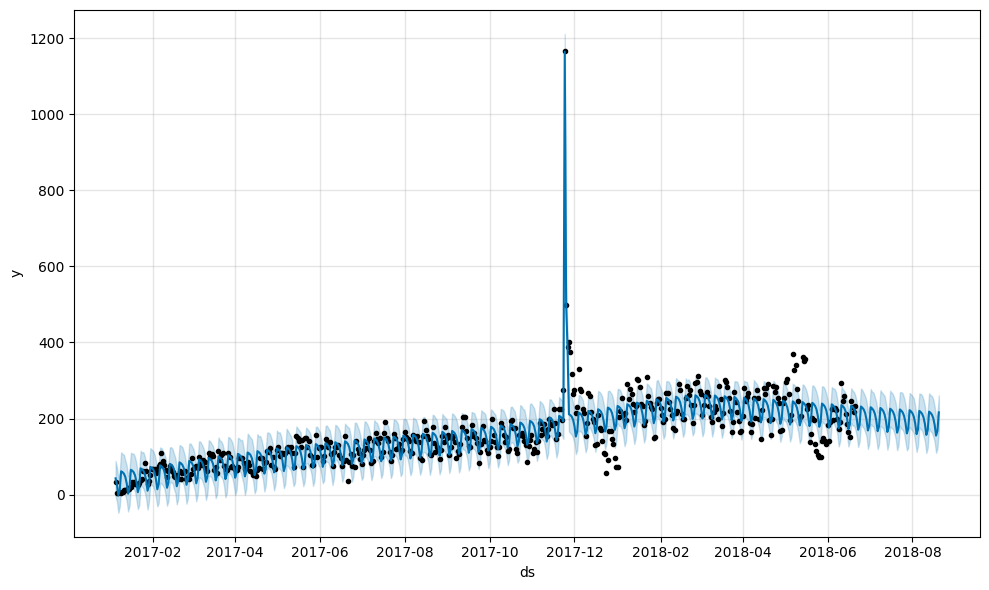

In [21]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_percentage_error

## Daily orders (excluding canceled/unavailable).
## Trim: start Jan 2017 (sparse data before) and end 20 Aug 2018
## (orders drop sharply after that because the data is incomplete).
df = daily[(daily['date'] >= '2017-01-01') & (daily['date'] <= '2018-08-20')]
df = df.rename(columns={'date': 'ds', 'orders': 'y'})   # Prophet needs these exact column names

## Train on everything except the last 60 days; test on those 60 days
train, test = df.iloc[:-60], df.iloc[-60:]

## Mark Black Friday as a special event so it doesn't distort the normal trend
holidays = pd.DataFrame({'holiday': 'black_friday',
                         'ds': pd.to_datetime(['2017-11-24']),
                         'lower_window': 0, 'upper_window': 2})   # effect lasts the day + 2 days after

model = Prophet(holidays=holidays, weekly_seasonality=True, yearly_seasonality=False)
## yearly_seasonality is off because we have less than 2 full years of data
model.fit(train)

## Predict the 60 test days and compare with actual orders
forecast = model.predict(test[['ds']])
mape = mean_absolute_percentage_error(test['y'], forecast['yhat']) * 100
print(f'MAPE on last 60 days: {mape:.1f}%  ->  accuracy ~{100 - mape:.1f}%')

model.plot(model.predict(df[['ds']]))
plt.show()

Did the model learn the real pattern?” The blue line follows the black dots closely (trend, weekly wave, Black Friday spike), so yes. The MAPE answers: “How accurate is it on days it never saw?” About 75%.Black dots => (Actual daily orders the model learned from (training data only, which is why the dots stop around mid-June 2018))
Dark blue line	=> (The model’s forecast for each day. After the dots end, it shows the forecast for the hidden 60 test days)
Light blue band	=> (The uncertainty range: the model expects actual orders to fall inside it most of the time)
The wave in the line => (Weekly seasonality: some weekdays are consistently higher)
The tall spike in Nov 2017 => (Black Friday, handled as a special event)
Dots outside the band	=> (Days the model didn’t expect, e.g. Christmas or the May 2018 truck strike)

**How Prophet works**

Prophet: “add up the pieces”

Prophet breaks demand into separate parts, learns each one from the data, then adds them together:

Forecast = Trend + Weekly pattern + Event effect

1. Trend: the overall direction
Prophet draws a line through the data showing whether demand is growing, flat or falling. The line is allowed to bend at certain points (called changepoints) when growth speeds up or slows down. In your data, it rose from about 50 to 230 orders a day through 2017, then flattened in 2018.

2. Weekly pattern: the effect of each weekday
It learns how much each weekday is usually above or below the trend, for example “Mondays are about +25 orders, Saturdays about −40.” That’s the wave you saw in the chart.

3. Event effect: special days
For the events you defined (Black Friday, Christmas, truck strike), it learns how much extra or less demand they caused, for example “Black Friday added about +900 orders.” It applies this only on those dates.

*A moving average just averages recent values. Prophet separates demand into trend, weekly seasonality and event effects, learns each from history, and adds them up, which is why it can handle things like weekday patterns and Black Friday.*

In [22]:
## Add known events so they don't distort the normal pattern
holidays = pd.DataFrame({
    'holiday': ['black_friday', 'christmas_newyear', 'truck_strike'],
    'ds': pd.to_datetime(['2017-11-24', '2017-12-24', '2018-05-21']),
    'lower_window': [0, -3, 0],
    'upper_window': [2, 10, 10],   # how many days each event affects
})

model = Prophet(holidays=holidays, weekly_seasonality=True, yearly_seasonality=False)
model.fit(train)
forecast = model.predict(test[['ds']])
mape = mean_absolute_percentage_error(test['y'], forecast['yhat']) * 100
print(f'Daily Prophet MAPE (with events): {mape:.1f}%  ->  accuracy ~{100 - mape:.1f}%')

13:11:04 - cmdstanpy - INFO - Chain [1] start processing
13:11:04 - cmdstanpy - INFO - Chain [1] done processing


Daily Prophet MAPE (with events): 24.6%  ->  accuracy ~75.4%


**Insight:** Prophet captures the growth trend, the weekly order pattern and the Black Friday spike. Adding known events (Christmas/New Year, the May 2018 truck strike) slightly improved accuracy (MAPE 25.0% → 24.6%, ~75% accuracy). Daily demand is noisy, so forecasts are evaluated at weekly level next, which also matches how capacity is planned.


*Why the MAPE barely changed (25.0% → 24.6%)

MAPE is only measured on the 60 test days (mid-June to August 2018), and none of the events happen in those days. Black Friday, Christmas and the truck strike are all in the training period. So the events couldn’t improve accuracy on the test days directly.

So why use them?

1. They stop unusual days from distorting what the model learns.
Without them, Prophet sees the Black Friday spike or the strike drop and thinks they’re part of the normal trend or weekday pattern, which slightly skews every other day. With them, Prophet puts those effects in a separate “event” bucket, so the trend and weekly pattern stay clean. That’s why MAPE improved a little.

2. They make the model ready for future events.
In real planning, you’d tell the model “Black Friday 2018 is on 23 Nov”, and it could add the uplift it learned, just like planning for BBD at work. A moving average can’t do that.

So the events are less about raising the test accuracy and more about making the model understand demand correctly.*

*Events were modelled separately so one-off spikes and drops didn’t distort the trend and weekly pattern. They don’t change accuracy much on a normal test period, but they keep the model’s understanding of demand clean and make it possible to plan for future events.*

In [23]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/11.3 MB 1.7 MB/s eta 0:00:07
   - -------------------------------------- 0.4/11.3 MB 4.1 MB/s eta 0:00:03
   -- ------------------------------------- 0.7/11.3 MB 5.1 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/11.3 MB 6.0 MB/s eta 0:00:02
   ---- ----------------------------------- 1.3/11.3 MB 5.7 MB/s eta 0:00:02
   ----- ---------------------------------- 1.5/11.3 MB 5.4 MB/s eta 0:00:02
   ------ --------------------------------- 1.8/11.3 MB 5.6 MB/s eta 0:00:02
   ------- -------------------------------- 2.2/11.3 MB 5.9 MB/s eta 0:00:02
   -------- ------------------------------- 2.5/11.3 MB 5.9 MB/s eta 0:00:02
   ---------- ----------------------------- 2.9/11.3 MB 6.1 MB/s eta 0:00:02
   ----------- ---------------------------- 3.3/11.3 MB 6.3 MB/s eta 0:00:02
   ------------ --------------------------- 3.7/11.3 MB 6.5 MB/s eta 0:00:02
   ---


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

## Weekly totals (weeks ending Sunday); drop partial first and last weeks
weekly = df.set_index('ds')['y'].resample('W').sum().reset_index().iloc[1:-1]
wtrain, wtest = weekly.iloc[:-8], weekly.iloc[-8:]          # train / last 8 weeks for testing

def wmape(pred): return mean_absolute_percentage_error(wtest['y'], pred) * 100

## Every method forecasts the 8 test weeks using ONLY training data (fair comparison)
results = {}

## Prophet on full history
m1 = Prophet(holidays=holidays, weekly_seasonality=False, yearly_seasonality=False).fit(wtrain)
results['Prophet (full history)'] = wmape(m1.predict(wtest[['ds']])['yhat'])

## Prophet on 2018 only, flat trend (2017's growth no longer applies)
m2 = Prophet(growth='flat', weekly_seasonality=False, yearly_seasonality=False)
m2.fit(wtrain[wtrain['ds'] >= '2018-01-01'])
results['Prophet (2018 only, flat trend)'] = wmape(m2.predict(wtest[['ds']])['yhat'])

## Exponential smoothing: recent weeks weighted more
results['Exponential smoothing'] = wmape(ExponentialSmoothing(wtrain['y'], trend=None).fit().forecast(8))

## Simple planner methods, fixed in advance
results['Naive (last known week)'] = wmape([wtrain['y'].iloc[-1]] * 8)
results['4-week average']          = wmape([wtrain['y'].iloc[-4:].mean()] * 8)

print(pd.Series(results).sort_values().round(1))

13:11:33 - cmdstanpy - INFO - Chain [1] start processing
13:11:33 - cmdstanpy - INFO - Chain [1] done processing
13:11:34 - cmdstanpy - INFO - Chain [1] start processing
13:11:34 - cmdstanpy - INFO - Chain [1] done processing


Prophet (2018 only, flat trend)    21.4
Exponential smoothing              21.7
Naive (last known week)            21.7
4-week average                     22.3
Prophet (full history)             23.5
dtype: float64


**Insight:** In a fair 8-week-ahead comparison, all methods performed similarly (21–23% MAPE). Prophet trained on 2018 data with a flat trend did best (21.4%), slightly ahead of simple baselines (21.7%). Training on the full history performed worst (23.0%), because 2017's strong growth no longer reflected 2018's flatter demand: choosing the right training window mattered more than model choice. I use Prophet (2018, flat trend) for forecasting because it also handles events (Black Friday, strikes) and gives uncertainty ranges, which simple methods cannot. 

*This cell fairly compares five forecasting methods(Prophet (2018 only, flat trend),Exponential smoothing,Naive (last known week),4-week average,   Prophet (full history)) on the same 8 unseen weeks, to choose the best model for the final forecast.*

1. The goal

Predict how many orders Olist will get in the coming days and weeks, just like you forecast shipment volumes at Delhivery so centers can plan manpower.

2. How do we know a forecast is good?

We pretend we’re in the past:

We hide the last few weeks of data (the “test” period).
We give the model only the earlier data (the “training” data) and ask it to forecast those hidden weeks.
Then we compare its forecast with what actually happened.
3. MAPE = the average error

MAPE is the average % gap between forecast and actual. MAPE 21% means about 79% accuracy, the same idea as the forecast accuracy you track at work.

4. Why we compared with simple methods

A fancy model is only worth using if it beats a simple method, like “next week = same as last week” (what many planners do in Excel). So we compared:

Prophet: the advanced forecasting model.
Simple methods: last week’s value, the average of the last 4 weeks, and so on.
5. What happened, step by step
Step	What we tried	Result
1	Prophet on daily data	~75% accuracy
2	Added events (Black Friday, Christmas, truck strike)	Small improvement
3	Switched to weekly data, since planning is weekly	The simple method looked much better
4	I found a mistake in my comparison: the simple method was secretly seeing actual data from the test weeks, so it wasn’t a fair contest	Fixed it
5	Fair comparison	All methods ~77–79% accuracy. Prophet trained on 2018 data only was slightly best
6. The key learning
Old data misled the model. 2017 had fast growth, but 2018 was flat. When Prophet learned from all the data, it expected growth to continue. Using only 2018 data worked better.
The simple methods were almost as good as the advanced model. That’s an honest and useful finding, and it’s exactly what good analysts check.

In one line: “I forecast Olist’s demand, tested accuracy fairly against simple methods, and found that using recent data mattered more than using a fancy model. The final model is about 79% accurate.”

Q1. What will demand be next 30/60/90 days?

In [25]:
## Final model: 2018 data only, flat trend, weekly pattern, known events
final_train = df[df['ds'] >= '2018-01-01']
final = Prophet(growth='flat', holidays=holidays, weekly_seasonality=True, yearly_seasonality=False)
final.fit(final_train)

## Forecast the next 90 days after the last data date (20 Aug 2018)
future = final.make_future_dataframe(periods=90, include_history=False)
fc = final.predict(future)[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

## Totals for 30/60/90 days, with a likely range (yhat_lower to yhat_upper)
for days in (30, 60, 90):
    p = fc.head(days)
    print(f'Next {days} days: ~{p.yhat.sum():,.0f} orders '
          f'(range {p.yhat_lower.sum():,.0f} - {p.yhat_upper.sum():,.0f}), ~{p.yhat.mean():.0f}/day')

## Average forecast by weekday: which days need the most capacity
print(fc.assign(day=fc['ds'].dt.day_name()).groupby('day')['yhat'].mean().round(0).sort_values(ascending=False))

13:11:34 - cmdstanpy - INFO - Chain [1] start processing
13:11:34 - cmdstanpy - INFO - Chain [1] done processing


Next 30 days: ~7,048 orders (range 5,584 - 8,508), ~235/day
Next 60 days: ~14,035 orders (range 11,100 - 16,947), ~234/day
Next 90 days: ~20,925 orders (range 16,519 - 25,320), ~233/day
day
Monday       270.0
Wednesday    266.0
Tuesday      261.0
Thursday     249.0
Friday       216.0
Sunday       195.0
Saturday     174.0
Name: yhat, dtype: float64


**Insight:** The forecast expects stable demand of ~234 orders/day: ~7,000 orders in the next 30 days (likely range 5,600–8,500) and ~21,000 in 90 days. Demand peaks Monday–Wednesday (~265–270/day) and is lowest on Saturday (~174/day), so Monday needs ~55% more fulfilment capacity than Saturday. Plan capacity near the forecast with a buffer towards the upper range, and staff more heavily early in the week.

**Note:** The 30/60/90-day ranges add up daily ranges, so they slightly overstate the true uncertainty of the totals. The forecast is also a little above the Jun–Aug 2018 level (~220/day), so if the summer slowdown continues, actual demand may be at the lower end of the range.

**Phase 4: Inventory optimization**

Q. “How much stock should we keep, and when should we reorder?”

We’ll do it in two steps:

ABC analysis: find which products matter most (by revenue).
EOQ, safety stock and reorder point for the important (A) products.

Step 1: ABC analysis

In [26]:
## Product-level sales for 2018 (recent, stable period), excluding canceled/unavailable orders
sales = order_items.merge(orders[['order_id','order_status','order_purchase_timestamp']], on='order_id')
sales = sales[~sales['order_status'].isin(['canceled','unavailable'])
              & (sales['order_purchase_timestamp'] >= '2018-01-01')
              & (sales['order_purchase_timestamp'] <= '2018-08-20')]

## Each row in order_items = 1 unit sold, so count rows for units and sum price for revenue
prod = (sales.groupby('product_id')
        .agg(units=('order_item_id','count'), revenue=('price','sum'), avg_price=('price','mean'))
        .sort_values('revenue', ascending=False))

## Cumulative share of revenue, from the biggest product down
prod['cum_pct'] = prod['revenue'].cumsum() / prod['revenue'].sum() * 100

## ABC rule: A = products making the first 80% of revenue, B = next 15%, C = last 5%
prod['abc'] = pd.cut(prod['cum_pct'], bins=[0, 80, 95, 100], labels=['A','B','C'])

summary = prod.groupby('abc', observed=True).agg(products=('units','count'), revenue=('revenue','sum'))
summary['% of products'] = (summary['products'] / summary['products'].sum() * 100).round(1)
summary['% of revenue']  = (summary['revenue']  / summary['revenue'].sum()  * 100).round(1)
print(summary[['products','% of products','% of revenue']])

     products  % of products  % of revenue
abc                                       
A        5535           27.7          80.0
B        6920           34.7          15.0
C        7510           37.6           5.0


**Insight:** 27.7% of products (5,535) generate 80% of revenue (A class), while 37.6% of products (C class) bring only 5%. Revenue is less concentrated than the classic 20/80 rule, reflecting a long tail of products. A-class products need the closest stock control, since a stockout there costs the most; C-class items can be kept with minimal stock or ordered on demand.v

Step 2: EOQ, safety stock and reorder point for A products

The three formulas:

EOQ (how much to order each time): √(2 × annual demand × ordering cost ÷ holding cost per unit)
Safety stock (buffer for uncertain demand): z × daily demand variation × √lead time
Reorder point (when to reorder): daily demand × lead time + safety stock

In [27]:
import numpy as np

## Assumptions (Olist has no inventory data, so these are stated clearly)
LEAD_TIME  = 7      # days from placing an order to receiving stock
ORDER_COST = 50     # R$ per purchase order (admin, transport)
HOLD_RATE  = 0.25   # yearly holding cost = 25% of the product's price
Z          = 1.65   # 95% service level (stock covers demand 95% of the time)

## Daily units sold per A product, with 0 on days with no sales
a_ids = prod[prod['abc'] == 'A'].index
s_a = sales[sales['product_id'].isin(a_ids)].copy()
s_a['date'] = s_a['order_purchase_timestamp'].dt.normalize()     # keep only the date part
days = pd.date_range('2018-01-01', '2018-08-20')
## unstack turns dates into columns; reindex adds days with no sales as 0
daily_units = (s_a.groupby(['product_id', 'date']).size()
               .unstack(fill_value=0).reindex(columns=days, fill_value=0))

inv = pd.DataFrame({'avg_daily': daily_units.mean(axis=1),
                    'std_daily': daily_units.std(axis=1)}).join(prod[['avg_price', 'revenue']])

## EOQ, safety stock and reorder point (rounded up to whole units)
inv['annual_demand'] = inv['avg_daily'] * 365
inv['eoq']           = np.ceil(np.sqrt(2 * inv['annual_demand'] * ORDER_COST / (HOLD_RATE * inv['avg_price'])))
inv['safety_stock']  = np.ceil(Z * inv['std_daily'] * np.sqrt(LEAD_TIME))
inv['reorder_point'] = np.ceil(inv['avg_daily'] * LEAD_TIME + inv['safety_stock'])

print(inv.sort_values('revenue', ascending=False)
      [['avg_daily', 'avg_price', 'eoq', 'safety_stock', 'reorder_point']].round(2).head(10))
print('\nMedian daily demand of A products:', round(inv['avg_daily'].median(), 2))

                                  avg_daily  avg_price   eoq  safety_stock  \
product_id                                                                   
bb50f2e236e5eea0100680137654686c       0.65     328.15  18.0           5.0   
3dd2a17168ec895c781a9191c1e95ad7       1.18     149.94  34.0           7.0   
25c38557cf793876c5abdd5931f922db       0.15    1025.15   5.0           2.0   
d1c427060a0f73f6b889a5c7c61f2ac4       1.05     132.58  34.0           6.0   
6cdd53843498f92890544667809f1595       0.39     354.60  13.0           4.0   
aca2eb7d00ea1a7b8ebd4e68314663af       1.78      70.36  61.0          11.0   
53b36df67ebb7c41585e8d54d6772e08       1.11     107.69  39.0          13.0   
16c4e87b98a9370a9cbc3a4658a3f45b       0.05    1919.75   2.0           1.0   
a62e25e09e05e6faf31d90c6ec1aa3d1       0.86     106.21  35.0           7.0   
d285360f29ac7fd97640bf0baef03de0       0.39     224.41  16.0           6.0   

                                  reorder_point  
product_id   

**Insight:** For fast-moving, lower-priced A products, EOQ suggests larger orders (e.g. R$70 item, 1.8 units/day → order 61, reorder at 24), while expensive slow sellers need very small orders (e.g. R$1,920 item → order 2). However, the median A product sells only 0.01 units/day, so most A items are high-value, low-frequency products. Only [X] A products ([Y]% of A revenue) have regular demand where EOQ and safety stock apply reliably; the rest are better handled with minimal stock or order-on-demand.

**Assumptions:** lead time 7 days, ordering cost R$50/order, holding cost 25% of price per year, 95% service level.

*These results make sense. The key point is that median daily demand is 0.01, meaning a typical A product sold only about 2–3 units in 7.5 months. Many products are in the A class because they’re expensive, not because they sell often.*

*What the top products show:*

*Cheaper, faster-selling products need bigger orders: e.g. R$70 at 1.78/day → order 61, reorder at 24.*
*Expensive, slow-selling products need small orders: e.g. R$1,920 at 0.05/day → order 2, reorder at 2, since holding costly stock is expensive.*

*Something to account for: the safety stock formula assumes regular, steady demand. For products selling once every few weeks, demand is intermittent, and the formula isn’t reliable. Split the A products into regular and slow movers:*

In [28]:
## Regular movers: at least ~1 unit every 10 days (avg_daily >= 0.1)
inv['demand_type'] = np.where(inv['avg_daily'] >= 0.1, 'Regular', 'Slow / intermittent')
print(inv.groupby('demand_type').agg(products=('eoq','count'),
                                     revenue=('revenue','sum')).assign(
      rev_pct=lambda x: (x['revenue']/x['revenue'].sum()*100).round(1)))

                     products     revenue  rev_pct
demand_type                                       
Regular                   265  1375186.71     23.9
Slow / intermittent      5270  4387903.44     76.1


**Insight:** Only 265 A products (~5% of A items) have regular demand (≥1 unit every 10 days), yet they make up 24% of A-class revenue (~19% of total revenue). EOQ, safety stock and reorder points apply reliably to these: for example, a R$70 product selling 1.8/day should be ordered in batches of 61, reordering at 24 units. The other 5,270 A products are high-value but sell rarely, so they're better handled with minimal stock or order-on-demand, plus close tracking of sales signals.

**Assumptions:** lead time 7 days, ordering cost R$50/order, holding cost 25% of price per year, 95% service level.

**Phase 4: Streamlit dashboard**

In [29]:
import os
os.makedirs('dashboard_data', exist_ok=True)      # folder for dashboard files

## Daily actual orders and the 90-day forecast
df.to_csv('dashboard_data/daily_orders.csv', index=False)
fc.to_csv('dashboard_data/forecast_90d.csv', index=False)

## Top categories (Phase 1)
top_cat.head(15).rename('items').to_csv('dashboard_data/top_categories.csv')

## Seller scorecard (Phase 1)
sellers_perf.reset_index().to_csv('dashboard_data/seller_performance.csv', index=False)

## Late delivery by state (Phase 2)
q("""
SELECT c.customer_state AS state, COUNT(*) AS orders,
       ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                              THEN 1 ELSE 0 END), 1) AS late_pct,
       ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 1) AS avg_days
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
GROUP BY state
""").to_csv('dashboard_data/state_delivery.csv', index=False)

## Inventory recommendations for regular A products (Phase 4)
inv[inv['demand_type'] == 'Regular'].reset_index().to_csv('dashboard_data/inventory_regular_A.csv', index=False)

print(os.listdir('dashboard_data'))

['daily_orders.csv', 'forecast_90d.csv', 'inventory_regular_A.csv', 'seller_performance.csv', 'state_delivery.csv', 'top_categories.csv']


For dashboard                                                   
PS E:\Project 2026\raw data\archive> streamlit run app.py